# Análisis espacio-temporal de la productividad primaria y la actividad pesquera aparente en Shiretoko, Japón

## Notebook 02. Descarga de datos oceanográficos (Copernicus Marine)

**Objetivo general:** Analizar la asociación espacio-temporal entre la variabilidad de la concentración superficial de clorofila-a y la distribución de la actividad pesquera.

**Variables oceanográficas que se descargan en este notebook:**

| Variable | Producto Copernicus Marine | Dataset ID | Resolución |
|---|---|---|---|
| Clorofila-a (CHL, mg m⁻³) | `OCEANCOLOUR_GLO_BGC_L4_MY_009_104` (multisensor) | `cmems_obs-oc_glo_bgc-plankton_my_l4-multi-4km_P1M` | 4 km, mensual |
| Temperatura superficial del mar (SST, °C) | `GLOBAL_MULTIYEAR_PHY_001_030` (reanálisis GLORYS12) | `cmems_mod_glo_phy_my_0.083deg_P1M-m` | 1/12° (~8 km), mensual |

**Periodo:** enero 2021 – diciembre 2025 (5 años, 60 meses).

**Área de estudio:** la definida en el Notebook 01 (42–46 °N, 143–148 °E).

**Integrantes:** Isabel Pérez, Victor Gómez, María Alejandra Cifuentes y Keynie Cauich-Tome.

**Proyecto:** OceanHackWeek 2026.

## 1. Instalar el Copernicus Marine Toolbox

La descarga se hace con la biblioteca oficial `copernicusmarine`. Solo hay que instalarla una vez en el servidor de Jupyter.

> Después de instalarla por primera vez, reinicia el kernel (*Kernel → Restart Kernel*) y continúa desde la siguiente celda.

In [1]:
%pip install -q --upgrade copernicusmarine

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
from getpass import getpass
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import copernicusmarine

print("copernicusmarine versión:", copernicusmarine.__version__)

copernicusmarine versión: 2.5.1


## 2. Autenticación: ¿se necesita un token?

**No se necesita token ni API key.** Copernicus Marine usa directamente el **usuario y contraseña** de tu cuenta (los mismos con los que entras a https://data.marine.copernicus.eu).

La función `copernicusmarine.login()` valida las credenciales y las guarda en un archivo de configuración en tu carpeta personal del servidor (`~/.copernicusmarine/.copernicusmarine-credentials`). **Solo hay que hacerlo una vez**; después, todas las descargas lo leen automáticamente.

⚠️ **Importante:** no escribas tu contraseña directamente en el notebook, sobre todo si lo van a subir a GitHub para OceanHackWeek. La celda siguiente la pide con `getpass`, que no la muestra ni la guarda en el notebook.

In [2]:
# Primero revisamos si ya hay credenciales válidas guardadas en el servidor
credenciales_ok = False
try:
    credenciales_ok = copernicusmarine.login(check_credentials_valid=True)
except Exception:
    credenciales_ok = False

if credenciales_ok:
    print("Ya hay credenciales válidas guardadas. No es necesario volver a ingresarlas.")
else:
    usuario = input("Usuario de Copernicus Marine: ")
    contrasena = getpass("Contraseña de Copernicus Marine: ")
    copernicusmarine.login(
        username=usuario,
        password=contrasena,
        force_overwrite=True
    )
    del contrasena
    print("Credenciales guardadas correctamente.")

INFO - 2026-11-19T03:40:23Z - Checking if credentials are valid.
INFO - 2026-11-19T03:40:23Z - No credentials found.
INFO - 2026-11-19T03:40:23Z - Please provide credentials as arguments or environment variables, or use the 'login' command to create a credentials file.


Usuario de Copernicus Marine:  vgomez
Contraseña de Copernicus Marine:  ········


INFO - 2026-11-19T03:40:35Z - Credentials file stored in /home/jovyan/.copernicusmarine/.copernicusmarine-credentials.


Credenciales guardadas correctamente.


## 3. Parámetros del área de estudio y del periodo

Se usan los mismos límites del Notebook 01.

In [3]:
# Límites geográficos (Notebook 01)
latitud_min = 42
latitud_max = 46
longitud_min = 143
longitud_max = 148

# Periodo: últimos 5 años, de 2025 hacia atrás
fecha_inicio = "2021-01-01T00:00:00"
fecha_fin = "2025-12-31T23:59:59"

# Carpeta donde se guardarán los datos
carpeta_datos = Path("datos") / "copernicus"
carpeta_datos.mkdir(parents=True, exist_ok=True)

# Identificadores de los datasets
DATASET_CHL = "cmems_obs-oc_glo_bgc-plankton_my_l4-multi-4km_P1M"
DATASET_SST = "cmems_mod_glo_phy_my_0.083deg_P1M-m"   # Reanálisis GLORYS12, mensual

print("Área:", latitud_min, "-", latitud_max, "°N |", longitud_min, "-", longitud_max, "°E")
print("Periodo:", fecha_inicio[:10], "a", fecha_fin[:10])
print("Carpeta de salida:", carpeta_datos.resolve())

Área: 42 - 46 °N | 143 - 148 °E
Periodo: 2021-01-01 a 2025-12-31
Carpeta de salida: /home/jovyan/tutoriales/18-miercoles/datos/copernicus


## 4. Revisar la cobertura temporal de cada dataset

Antes de descargar, abrimos los datasets en modo *lazy* (sin descargar los valores) para confirmar qué fechas cubren. Esto evita sorpresas, porque los productos reprocesados y de reanálisis se actualizan con algunos meses de retraso.

In [4]:
def cobertura(dataset_id, variable):
    ds = copernicusmarine.open_dataset(
        dataset_id=dataset_id,
        variables=[variable],
        minimum_longitude=longitud_min,
        maximum_longitude=longitud_max,
        minimum_latitude=latitud_min,
        maximum_latitude=latitud_max,
    )
    t0 = pd.Timestamp(ds.time.values.min())
    t1 = pd.Timestamp(ds.time.values.max())
    print(f"{dataset_id}\n   {variable}: {t0:%Y-%m-%d} a {t1:%Y-%m-%d}")
    return t0, t1

chl_inicio, chl_fin = cobertura(DATASET_CHL, "CHL")
sst_inicio, sst_fin = cobertura(DATASET_SST, "thetao")

INFO - 2026-11-19T03:41:18Z - Selected dataset version: "202603"
INFO - 2026-11-19T03:41:18Z - Selected dataset part: "default"
WARNING - 2026-11-19T03:41:18Z - You are using the dataset cmems_obs-oc_glo_bgc-plankton_my_l4-multi-4km_P1M, version '202603', part 'default'. This exact version and part of the dataset will be retired on the 2026-11-24T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information


cmems_obs-oc_glo_bgc-plankton_my_l4-multi-4km_P1M
   CHL: 1997-09-01 a 2026-10-01


INFO - 2026-11-19T03:41:24Z - Selected dataset version: "202311"
INFO - 2026-11-19T03:41:24Z - Selected dataset part: "default"


cmems_mod_glo_phy_my_0.083deg_P1M-m
   thetao: 1993-01-01 a 2026-09-01


## 5. Descargar la clorofila-a mensual (CHL)

El producto multisensor L4 mensual ya viene promediado por mes, así que se descarga tal cual con `copernicusmarine.subset()`. El resultado es un archivo NetCDF.

In [5]:
archivo_chl = "CHL_mensual_Shiretoko_2021_2025.nc"

copernicusmarine.subset(
    dataset_id=DATASET_CHL,
    variables=["CHL"],
    minimum_longitude=longitud_min,
    maximum_longitude=longitud_max,
    minimum_latitude=latitud_min,
    maximum_latitude=latitud_max,
    start_datetime=fecha_inicio,
    end_datetime=fecha_fin,
    output_directory=str(carpeta_datos),
    output_filename=archivo_chl,
    overwrite=True,
)

print("CHL descargada en:", carpeta_datos / archivo_chl)

INFO - 2026-11-19T03:41:49Z - Selected dataset version: "202603"
INFO - 2026-11-19T03:41:49Z - Selected dataset part: "default"
WARNING - 2026-11-19T03:41:49Z - You are using the dataset cmems_obs-oc_glo_bgc-plankton_my_l4-multi-4km_P1M, version '202603', part 'default'. This exact version and part of the dataset will be retired on the 2026-11-24T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information
INFO - 2026-11-19T03:41:54Z - Total size of the download: 2.65 MB.


CHL descargada en: datos/copernicus/CHL_mensual_Shiretoko_2021_2025.nc


## 6. Descargar la SST mensual del reanálisis (GLORYS12)

El reanálisis GLORYS12 entrega la temperatura potencial del mar (`thetao`) en 50 niveles de profundidad. La **SST** corresponde al nivel más superficial (~0.5 m), así que se descarga solo ese nivel (`minimum_depth=0`, `maximum_depth=1`).

El dataset ya es mensual y viene en °C, así que no hace falta promediar ni convertir unidades. Al final se guarda un archivo limpio con una sola variable llamada `SST`.

In [6]:
archivo_sst_crudo = "thetao_superficie_GLORYS12_2021_2025.nc"

copernicusmarine.subset(
    dataset_id=DATASET_SST,
    variables=["thetao"],
    minimum_longitude=longitud_min,
    maximum_longitude=longitud_max,
    minimum_latitude=latitud_min,
    maximum_latitude=latitud_max,
    minimum_depth=0,
    maximum_depth=1,
    start_datetime=fecha_inicio,
    end_datetime=fecha_fin,
    output_directory=str(carpeta_datos),
    output_filename=archivo_sst_crudo,
    overwrite=True,
)

# Dejar solo la SST: quitar la dimensión de profundidad y renombrar la variable
ds_crudo = xr.open_dataset(carpeta_datos / archivo_sst_crudo)
profundidad = float(ds_crudo["depth"].values[0])

ds_sst = (
    ds_crudo["thetao"]
    .isel(depth=0, drop=True)
    .rename("SST")
    .to_dataset()
)
ds_sst["SST"].attrs = {
    "units": "degC",
    "long_name": f"Temperatura superficial del mar (thetao a {profundidad:.2f} m, promedio mensual)",
}
ds_sst.attrs = {
    "fuente": "Copernicus Marine, GLOBAL_MULTIYEAR_PHY_001_030 (GLORYS12), " + DATASET_SST,
    "area": f"{latitud_min}-{latitud_max}N, {longitud_min}-{longitud_max}E",
}

archivo_sst = carpeta_datos / "SST_mensual_Shiretoko_2021_2025.nc"
ds_sst.load().to_netcdf(archivo_sst)
ds_crudo.close()

print(f"Nivel usado como SST: {profundidad:.2f} m")
print("SST mensual guardada en:", archivo_sst)

INFO - 2026-11-19T03:42:11Z - Selected dataset version: "202311"
INFO - 2026-11-19T03:42:11Z - Selected dataset part: "default"
WARNING - 2026-11-19T03:42:11Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
INFO - 2026-11-19T03:42:18Z - Total size of the download: 365.11 KB.


Nivel usado como SST: 0.49 m
SST mensual guardada en: datos/copernicus/SST_mensual_Shiretoko_2021_2025.nc


## 7. Verificar los datos descargados

In [7]:
chl = xr.open_dataset(carpeta_datos / archivo_chl)
sst = xr.open_dataset(archivo_sst)

print("CHL:", dict(chl.sizes), "| meses:", chl.sizes["time"])
print("SST:", dict(sst.sizes), "| meses:", sst.sizes["time"])
print()
print("Primer y último mes CHL:", str(chl.time.values[0])[:7], "-", str(chl.time.values[-1])[:7])
print("Primer y último mes SST:", str(sst.time.values[0])[:7], "-", str(sst.time.values[-1])[:7])

# Porcentaje de píxeles oceánicos sin dato de CHL por mes
# (en invierno es normal tener huecos por nubes, hielo y bajo ángulo solar)
faltantes = chl["CHL"].isnull().mean(dim=["latitude", "longitude"]) * 100
print("\nMeses con más del 50 % de píxeles sin CHL:")
print(faltantes.where(faltantes > 50, drop=True).to_series().round(1))

CHL: {'time': 60, 'latitude': 96, 'longitude': 120} | meses: 60
SST: {'time': 60, 'latitude': 49, 'longitude': 61} | meses: 60

Primer y último mes CHL: 2021-01 - 2025-12
Primer y último mes SST: 2021-01 - 2025-12

Meses con más del 50 % de píxeles sin CHL:
Series([], Name: CHL, dtype: float64)


/srv/conda/envs/notebook/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/srv/conda/envs/notebook/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


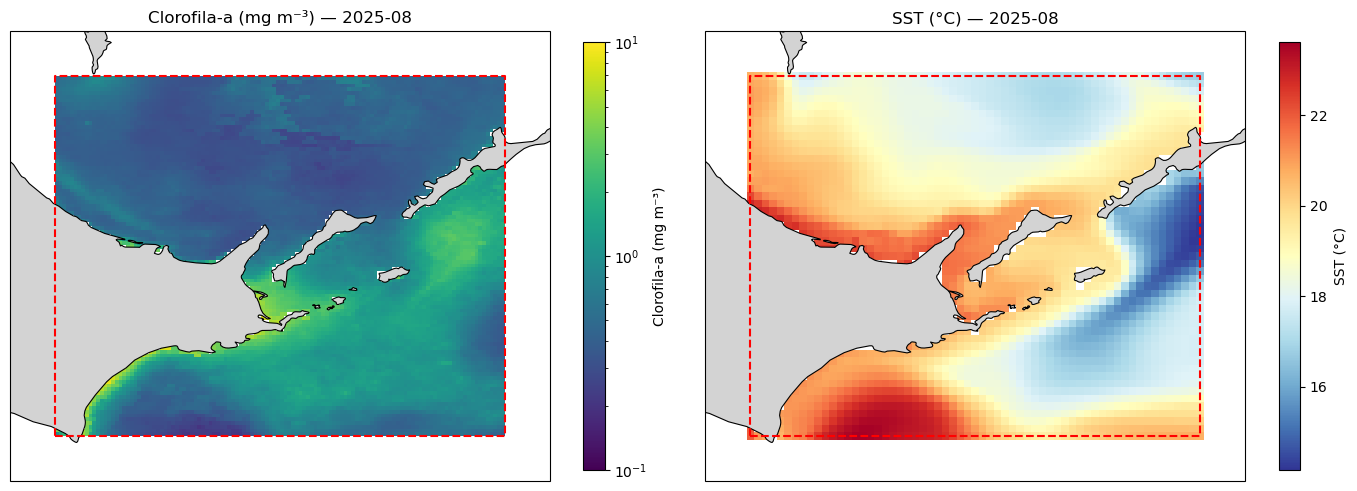

In [8]:
# Mapas de un mes de ejemplo (agosto 2025)
mes = "2025-08"

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

campos = [
    (chl["CHL"].sel(time=mes).squeeze(), "Clorofila-a (mg m⁻³)", "viridis", True),
    (sst["SST"].sel(time=mes).squeeze(), "SST (°C)", "RdYlBu_r", False),
]

for ax, (campo, titulo, cmap, escala_log) in zip(axes, campos):
    ax.set_extent([142.5, 148.5, 41.5, 46.5], crs=ccrs.PlateCarree())
    if escala_log:
        from matplotlib.colors import LogNorm
        im = campo.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap,
                        norm=LogNorm(vmin=0.1, vmax=10), add_colorbar=False)
    else:
        im = campo.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, add_colorbar=False)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    ax.plot([longitud_min, longitud_max, longitud_max, longitud_min, longitud_min],
            [latitud_min, latitud_min, latitud_max, latitud_max, latitud_min],
            color="red", linestyle="--", linewidth=1.5, transform=ccrs.PlateCarree(), zorder=4)
    plt.colorbar(im, ax=ax, shrink=0.75, label=titulo)
    ax.set_title(f"{titulo} — {mes}")

plt.tight_layout()
plt.show()

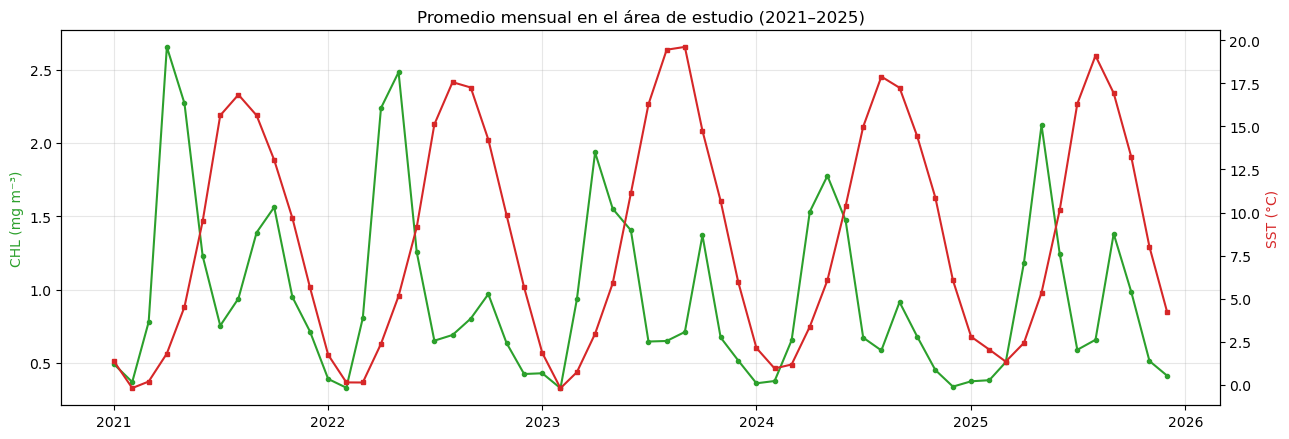

In [9]:
# Series de tiempo del promedio espacial en el área de estudio
# Para CHL se usa la media geométrica (la CHL tiene distribución log-normal)
chl_serie = np.exp(np.log(chl["CHL"]).mean(dim=["latitude", "longitude"]))
sst_serie = sst["SST"].mean(dim=["latitude", "longitude"])

fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.plot(chl_serie.time, chl_serie, color="tab:green", marker="o", markersize=3, label="CHL")
ax1.set_ylabel("CHL (mg m⁻³)", color="tab:green")

ax2 = ax1.twinx()
ax2.plot(sst_serie.time, sst_serie, color="tab:red", marker="s", markersize=3, label="SST")
ax2.set_ylabel("SST (°C)", color="tab:red")

ax1.set_title("Promedio mensual en el área de estudio (2021–2025)")
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()